In [1]:
import pandas as pd
import string as str
import numpy as np
from imblearn.under_sampling import RandomUnderSampler
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder,OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error,r2_score,confusion_matrix,accuracy_score,ConfusionMatrixDisplay,precision_score,f1_score,recall_score,roc_auc_score,classification_report
import seaborn as sns
from imblearn.over_sampling import SMOTE


In [2]:
df=pd.read_csv("tumor.csv")

In [3]:
df

,Age,Gender,Country,Tumor_Size,Tumor_Location,MRI_Findings,Genetic_Risk,Smoking_History,Alcohol_Consumption,Radiation_Exposure,...,Blood_Pressure_Sys,Blood_Pressure_Dia,Tumor_Type,Treatment_Received,Survival_Rate(%),Tumor_Growth_Rate,Family_History,Symptom_Severity,Brain_int,Brain_Tumor_Present
0,66,Other,China,8.70,Cerebellum,Severe,81,No,Yes,Medium,...,122,88,Malignant,NaN,58,Slow,Yes,Mild,0,No
1,87,Female,Australia,8.14,Temporal,Normal,65,No,Yes,Medium,...,126,119,Malignant,NaN,13,Rapid,Yes,Severe,0,No
2,41,Male,Canada,6.02,Occipital,Severe,100,Yes,No,Low,...,118,65,Benign,Chemotherapy,67,Slow,Yes,Moderate,1,Yes
3,52,Male,Japan,7.26,Occipital,Normal,19,Yes,Yes,High,...,165,119,Benign,Radiation,85,Moderate,No,Moderate,1,Yes
4,84,Female,Brazil,7.94,Temporal,Abnormal,47,No,Yes,Medium,...,156,97,Malignant,NaN,17,Moderate,No,Moderate,0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,77,Female,Germany,2.05,Frontal,Normal,9,Yes,Yes,High,...,93,80,Benign,Chemotherapy,36,Rapid,Yes,Mild,0,No
249996,89,Other,Japan,3.55,Parietal,Normal,75,Yes,No,Low,...,119,112,Benign,Radiation,80,Slow,Yes,Moderate,1,Yes
249997,16,Other,Russia,8.54,Temporal,Normal,52,No,Yes,Low,...,101,68,Malignant,Radiation,72,Slow,No,Severe,1,Yes
249998,56,Other,Germany,2.17,Cerebellum,Severe,95,Yes,No,High,...,179,106,Benign,NaN,83,Rapid,Yes,Moderate,1,Yes


In [4]:
df.columns

Index(['Age', 'Gender', 'Country', 'Tumor_Size', 'Tumor_Location',
       'MRI_Findings', 'Genetic_Risk', 'Smoking_History',
       'Alcohol_Consumption', 'Radiation_Exposure', 'Head_Injury_History',
       'Chronic_Illness', 'Diabetes', 'Blood_Pressure_Sys',
       'Blood_Pressure_Dia', 'Tumor_Type', 'Treatment_Received',
       'Survival_Rate(%)', 'Tumor_Growth_Rate', 'Family_History',
       'Symptom_Severity', 'Brain_int', 'Brain_Tumor_Present'],
      dtype='object')

In [39]:
# Make a copy of X to avoid SettingWithCopyWarning
X = df[['Age', 'Tumor_Size', 'Genetic_Risk',  'Tumor_Type',  'Survival_Rate(%)', 'Family_History']].copy()
# Initialize LabelEncoder for the other columns
label_encoder = LabelEncoder()

# Label encode 'Tumor_Type', 'Treatment_Received', 'Tumor_Growth_Rate', 'Family_History'
X['Tumor_Type'] = label_encoder.fit_transform(X['Tumor_Type'])
X['Family_History'] = label_encoder.fit_transform(X['Family_History'])

# Check the encoded data
print(X.head())

# Target variable
Y = df['Brain_int']


   Age  Tumor_Size  Genetic_Risk  Tumor_Type  Survival_Rate(%)  Family_History
0   66        8.70            81           1                58               1
1   87        8.14            65           1                13               1
2   41        6.02           100           0                67               1
3   52        7.26            19           0                85               0
4   84        7.94            47           1                17               0


In [40]:
Y=Y.astype(int)
smote = SMOTE(random_state=42)
X_resampled, Y_resampled = smote.fit_resample(X, Y)
X_train, X_test, Y_train, Y_test = train_test_split(X_resampled, Y_resampled, test_size=0.3, random_state=42)

<Axes: xlabel='Brain_int', ylabel='count'>

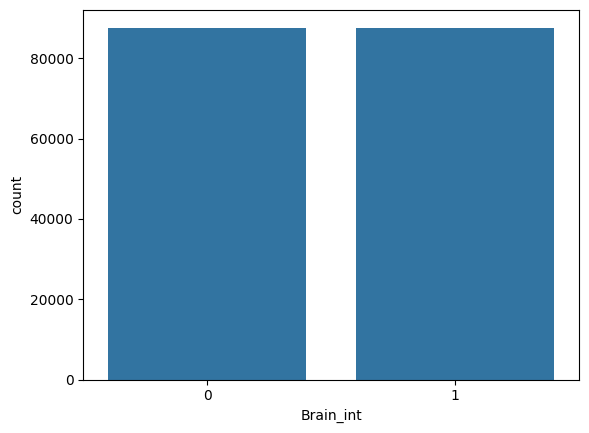

In [41]:
import seaborn as sns
sns.countplot(x=Y_train)

In [42]:
# import matplotlib.pyplot as plt

# plt.figure(figsize=(10,8))
# sns.heatmap(X_train.corr(), annot=True, cmap="coolwarm", fmt=".2f")
# plt.title("Feature Correlation Matrix")
# plt.show()
# df['Brain_int'].value_counts()


In [43]:
# from sklearn.model_selection import cross_val_score
# cv_scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), 
# X_train, Y_train, cv=5, scoring='accuracy')

# print("Cross-validation Accuracy:", cv_scores.mean())


In [44]:
# from sklearn.ensemble import RandomForestClassifier
# import pandas as pd
# import matplotlib.pyplot as plt

# # Train RandomForest to check feature importance
# rf = RandomForestClassifier(n_estimators=100, random_state=42)
# rf.fit(X_train, Y_train)

# # Get feature importance
# feature_importances = pd.Series(rf.feature_importances_, index=X_train.columns)

# # Plot feature importances
# plt.figure(figsize=(10, 6))
# feature_importances.sort_values().plot(kind="barh", color="skyblue")
# plt.xlabel("Feature Importance Score")
# plt.ylabel("Features")
# plt.title("Feature Importance in RandomForest")
# plt.show()

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [81]:
from keras.models import Sequential
from keras.layers import Dense,LeakyReLU
from tensorflow.keras.optimizers import Adam


model = Sequential([
    Dense(64, input_dim=X_train.shape[1], activation="linear"),  
    LeakyReLU(alpha=0.01),  # Alpha determines the negative slope (default is 0.3)
    Dense(64,activation="relu"),
    Dense(64,activation="relu"),
    LeakyReLU(alpha=0.01),
    LeakyReLU(alpha=0.01),
    Dense(8),
    Dense(1, activation='sigmoid')  # Binary classification output
])
optimizer = Adam(learning_rate=0.00008,clipnorm=1.0)

model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_train_scaled, Y_train, epochs=5, batch_size=64, validation_split=0.4)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test_scaled, Y_test)
print(f"Test Accuracy: {test_acc}")

Epoch 1/5


c:\Users\Lakshin Khurana\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\Lakshin Khurana\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


1643/1643 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4993 - loss: 0.6952 - val_accuracy: 0.5012 - val_loss: 0.6937
Epoch 2/5
1643/1643 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5039 - loss: 0.6934 - val_accuracy: 0.5013 - val_loss: 0.6935
Epoch 3/5
1643/1643 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.5068 - loss: 0.6930 - val_accuracy: 0.5021 - val_loss: 0.6936
Epoch 4/5
1643/1643 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5094 - loss: 0.6929 - val_accuracy: 0.5013 - val_loss: 0.6936
Epoch 5/5
1643/1643 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5112 - loss: 0.6926 - val_accuracy: 0.4999 - val_loss: 0.6937
2346/2346 ━━━━━━━━━━━━━━━━━━━━ 1s 501us/step - accuracy: 0.5018 - loss: 0.6937
Test Accuracy: 0.5004462599754333


In [82]:
Y_pred = model.predict(X_test)
Y_pred = (Y_pred > 0.5).astype(int) 
cm=confusion_matrix(Y_test,Y_pred)

2346/2346 ━━━━━━━━━━━━━━━━━━━━ 1s 470us/step


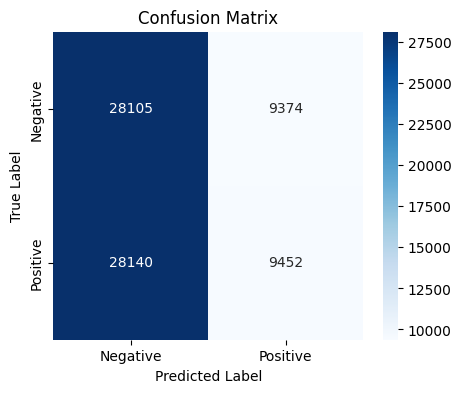

In [83]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [49]:
neg, pos = np.bincount(Y_train)  # Counts the number of 0s and 1s
total = neg + pos

print(f"Negative Samples: {neg} ({neg / total:.2%})")
print(f"Positive Samples: {pos} ({pos / total:.2%})")


Negative Samples: 87639 (50.03%)
Positive Samples: 87526 (49.97%)


In [85]:
logits = model(X_train_scaled)  # Logits before sigmoid
print(logits[:10])  # Inspect logits


tf.Tensor(
[[0.49803996]
 [0.4714828 ]
 [0.47829735]
 [0.48461646]
 [0.47604996]
 [0.5090275 ]
 [0.5011072 ]
 [0.49100745]
 [0.5094559 ]
 [0.46439025]], shape=(10, 1), dtype=float32)
